# 02 — Probability & Statistics for ML

**Overview:** probability, conditional probability, Bayes' theorem, random variables and
distributions, expected value/variance/covariance/correlation, and sampling.

**Required libraries:** `numpy`, `matplotlib`.

Connects to: `01_linear_algebra.ipynb` (covariance matrices reused PCA's eigendecomposition).
Leads to: `03_calculus_and_gradient_descent.ipynb`.

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **ML** | Machine Learning | Learning patterns from data to make predictions, instead of hand-coding rules. |
| **PCA** | Principal Component Analysis | Linear dimensionality reduction: projects data onto orthogonal directions of maximum variance. |
| **CLT** | Central Limit Theorem | Means of many independent samples are approximately normally distributed. |
| **SGD** | Stochastic Gradient Descent | Gradient descent using a mini-batch/single sample per update. |

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("numpy:", np.__version__)
rng = np.random.default_rng(42)


numpy: 2.5.3


## 1. Probability and conditional probability

💡 **Intuition:** `P(A|B)` is "the probability of A, given that we already know B happened" —
restricting the sample space to the cases where B is true.

In [2]:
# Simulate 100,000 patients: 1% have a disease; among those with it, 90% test positive
# (sensitivity); among those without it, 5% still test positive (false positive rate).
n = 100_000
has_disease = rng.random(n) < 0.01
test_positive = np.where(
    has_disease,
    rng.random(n) < 0.90,   # true positive rate
    rng.random(n) < 0.05,   # false positive rate
)

p_disease = has_disease.mean()
p_positive_given_disease = test_positive[has_disease].mean()
p_positive_given_healthy = test_positive[~has_disease].mean()

print(f"P(disease)            ~ {p_disease:.4f}")
print(f"P(positive | disease) ~ {p_positive_given_disease:.4f}")
print(f"P(positive | healthy) ~ {p_positive_given_healthy:.4f}")


P(disease)            ~ 0.0105
P(positive | disease) ~ 0.8930
P(positive | healthy) ~ 0.0492


## 2. Bayes' theorem

**Equation:** `P(A|B) = P(B|A) P(A) / P(B)`

⚠️ **Common Mistake (base-rate fallacy):** a 90%-sensitive test on a rare (1%) disease still
produces *mostly false positives* among everyone who tests positive — ignoring the base rate
`P(disease)` leads to wildly overconfident conclusions.

In [3]:
p_positive = test_positive.mean()  # empirical P(positive), via simulation

# Bayes' theorem: P(disease | positive) = P(positive | disease) * P(disease) / P(positive)
p_disease_given_positive_bayes = (p_positive_given_disease * p_disease) / p_positive

# Cross-check against the direct empirical estimate from the simulation.
p_disease_given_positive_empirical = has_disease[test_positive].mean()

print(f"P(disease | positive) via Bayes' theorem: {p_disease_given_positive_bayes:.4f}")
print(f"P(disease | positive) via direct simulation: {p_disease_given_positive_empirical:.4f}")
print(f"\nEven with a 90%-sensitive test, only ~{p_disease_given_positive_bayes:.0%} of positive "
      "results are true cases, because the disease is rare (1%) -- most positives are false "
      "alarms from the much larger healthy population.")

assert abs(p_disease_given_positive_bayes - p_disease_given_positive_empirical) < 0.02


P(disease | positive) via Bayes' theorem: 0.1612
P(disease | positive) via direct simulation: 0.1612

Even with a 90%-sensitive test, only ~16% of positive results are true cases, because the disease is rare (1%) -- most positives are false alarms from the much larger healthy population.


## 3. Random variables and distributions

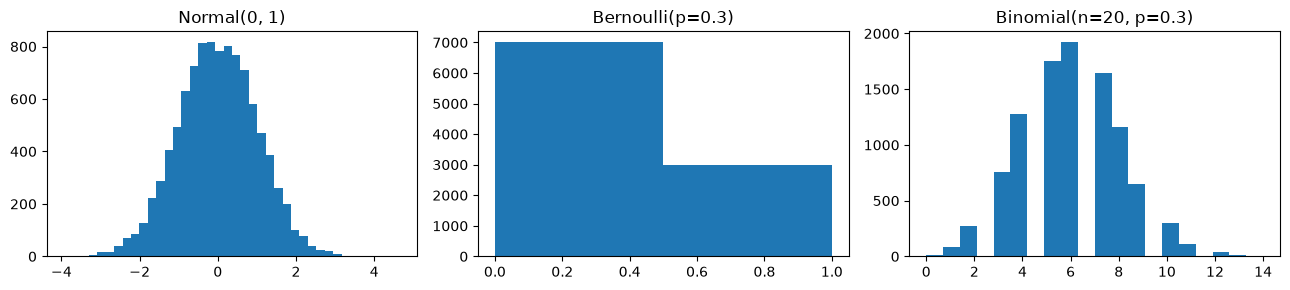

empirical mean of Bernoulli(0.3): 0.2987 (theoretical: 0.3)


In [4]:
normal_samples = rng.normal(loc=0, scale=1, size=10_000)
bernoulli_samples = rng.binomial(n=1, p=0.3, size=10_000)
binomial_samples = rng.binomial(n=20, p=0.3, size=10_000)

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].hist(normal_samples, bins=40); axes[0].set_title("Normal(0, 1)")
axes[1].hist(bernoulli_samples, bins=2); axes[1].set_title("Bernoulli(p=0.3)")
axes[2].hist(binomial_samples, bins=20); axes[2].set_title("Binomial(n=20, p=0.3)")
plt.tight_layout(); plt.show()

print("empirical mean of Bernoulli(0.3):", bernoulli_samples.mean(), "(theoretical: 0.3)")
assert abs(bernoulli_samples.mean() - 0.3) < 0.02


## 4. Expected value, variance, covariance, correlation

**Equations:** `E[X] = Σ x P(x)`, `Var(X) = E[(X - E[X])²]`,
`Cov(X,Y) = E[(X - E[X])(Y - E[Y])]`, `Corr(X,Y) = Cov(X,Y) / (σX σY)` (normalized to `[-1, 1]`).

In [5]:
x = rng.normal(size=5000)
y_correlated = 0.7 * x + rng.normal(scale=0.5, size=5000)
y_independent = rng.normal(size=5000)

print("E[x] ~", x.mean(), " Var(x) ~", x.var())

cov_matrix_correlated = np.cov(x, y_correlated)
cov_matrix_independent = np.cov(x, y_independent)
corr_correlated = np.corrcoef(x, y_correlated)[0, 1]
corr_independent = np.corrcoef(x, y_independent)[0, 1]

print("\nCov(x, y_correlated):\n", cov_matrix_correlated)
print("Corr(x, y_correlated):", corr_correlated)
print("\nCov(x, y_independent):\n", cov_matrix_independent)
print("Corr(x, y_independent):", corr_independent)

assert corr_correlated > 0.6          # constructed to be strongly correlated
assert abs(corr_independent) < 0.05   # constructed to be independent


E[x] ~ -0.0162757891443127  Var(x) ~ 0.9780584563510685

Cov(x, y_correlated):
 [[0.97825411 0.68921535]
 [0.68921535 0.73117234]]
Corr(x, y_correlated): 0.8149279688902846

Cov(x, y_independent):
 [[0.97825411 0.00863549]
 [0.00863549 0.99269609]]
Corr(x, y_independent): 0.00876300379709655


⚠️ **Common Mistake:** correlation ≠ causation. `y_correlated` is correlated with `x` purely
by construction (`y = 0.7x + noise`) — no causal claim is being made or justified by the
correlation coefficient alone.

## 5. Sampling

💡 **Intuition:** sampling is how train/test splits, bootstrapping, and stochastic gradient
descent's mini-batches all work — drawing a subset to estimate something about the whole.

In [6]:
population = rng.normal(loc=50, scale=10, size=1_000_000)
print("true population mean:", population.mean())

sample_means = [rng.choice(population, size=100, replace=False).mean() for _ in range(500)]
print("mean of 500 sample-means (size 100 each):", np.mean(sample_means))
print("std of those sample-means (standard error):", np.std(sample_means))

# Law of large numbers / CLT intuition: sample means cluster tightly around the true mean.
assert abs(np.mean(sample_means) - population.mean()) < 0.5


true population mean: 50.01441524017511
mean of 500 sample-means (size 100 each): 50.041961645725706
std of those sample-means (standard error): 0.982719028750419


## 6. Connection to what's next

Expected value and gradients are deeply linked: the gradient of an expected loss over a dataset
is itself an expectation — this is exactly why mini-batch SGD (sampling a subset) gives an
*unbiased estimate* of the full-dataset gradient, covered in Day 2's optimization topic.
`03_calculus_and_gradient_descent.ipynb` picks up the calculus side next.

## 7. Interview questions
1. Walk through Bayes' theorem and explain why a rare disease with a sensitive test still produces mostly false positives among positive results.
2. What's the difference between covariance and correlation, and why is correlation easier to interpret across different variables?
3. Why can two variables be strongly correlated without one causing the other?
4. What does the standard error of the mean tell you, and how does sample size affect it?
5. What's the difference between a Bernoulli and a Binomial distribution?

## 8. Exercises
1. Change the disease simulation's base rate from 1% to 20% and observe how `P(disease | positive)` changes.
2. Simulate two variables with a *negative* correlation and verify the sign of the correlation coefficient.
3. Estimate π via Monte Carlo sampling (random points in a unit square, fraction inside the inscribed circle).

## 9. Summary

✅ Bayes' theorem corrects for base rates; covariance/correlation quantify (linear) relationships
between variables; sampling underlies train/test splitting and mini-batch training. Next:
`03_calculus_and_gradient_descent.ipynb`.